In [1]:
import pandas as pd
import matplotlib as mtp
import numpy as np
from pathlib import Path

In [2]:
# busco la nueva carpeta con los datos limpios y ordenados

escritorio = Path.home() / "Desktop"
carpeta_limpios = escritorio / "datos_futbol_limpios"

In [3]:
# creo un diccionario para guardar los df limpios

dataframes = {}

for archivo in carpeta_limpios.glob("*.csv"):
    # guardo los archivos sin la extension .csv
    nombre_archivo = archivo.stem
    dataframes[nombre_archivo] = pd.read_csv(archivo)
    print(f"Cargado correctamente: {nombre_archivo}")

Cargado correctamente: marcadores_limpio
Cargado correctamente: paises_limpio
Cargado correctamente: penalties_limpio
Cargado correctamente: resultados_limpio


In [8]:
# el notebook carga los CSV dentro del diccionario dataframes, 
# pero no crea una variable independiente llamada marcadores_limpio, que me hace falta para el punto 1.2

marcadores_limpio = dataframes["marcadores_limpio"]

## verifico que esté bien y me saco el shape de unos de los df, los demás estarán bien

In [8]:
print("\nDimensiones de resultados_limpio:", dataframes["resultados_limpio"].shape)
print("\nDimensiones de marcadores_limpio:", dataframes["marcadores_limpio"].shape)
print("\nDimensiones de penalties_limpio:", dataframes["penalties_limpio"].shape)
print("\nDimensiones de paises_limpio:", dataframes["paises_limpio"].shape)


Dimensiones de resultados_limpio: (49945, 9)

Dimensiones de marcadores_limpio: (47914, 8)

Dimensiones de penalties_limpio: (700, 5)

Dimensiones de paises_limpio: (36, 4)


In [9]:
print(dataframes.keys())

dict_keys(['marcadores_limpio', 'paises_limpio', 'penalties_limpio', 'resultados_limpio'])


In [10]:
for nombre, df in dataframes.items():
    print(f"\n--- {nombre} ---")
    df.info()


--- marcadores_limpio ---
<class 'pandas.DataFrame'>
RangeIndex: 47914 entries, 0 to 47913
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   date       47914 non-null  str  
 1   home_team  47914 non-null  str  
 2   away_team  47914 non-null  str  
 3   team       47914 non-null  str  
 4   scorer     47914 non-null  str  
 5   minute     47914 non-null  str  
 6   own_goal   47914 non-null  bool 
 7   penalty    47914 non-null  bool 
dtypes: bool(2), str(6)
memory usage: 2.3 MB

--- paises_limpio ---
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   current     36 non-null     str  
 1   former      36 non-null     str  
 2   start_date  36 non-null     str  
 3   end_date    36 non-null     str  
dtypes: str(4)
memory usage: 1.3 KB

--- penalties_limpio ---
<class 'pandas.DataFrame'>
RangeIndex: 70

## las fechas siguen siendo str, las paso en formato fecha

In [7]:
dataframes["resultados_limpio"]["date"] = pd.to_datetime(dataframes["resultados_limpio"]["date"])
dataframes["marcadores_limpio"]["date"] = pd.to_datetime(dataframes["marcadores_limpio"]["date"])
dataframes["penalties_limpio"]["date"] = pd.to_datetime(dataframes["penalties_limpio"]["date"])
dataframes["paises_limpio"]["start_date"] = pd.to_datetime(dataframes["paises_limpio"]["start_date"])
dataframes["paises_limpio"]["end_date"] = pd.to_datetime(dataframes["paises_limpio"]["end_date"])


In [8]:
for nombre, df in dataframes.items():
    print(f"\n--- {nombre} ---")
    df.info()


--- marcadores_limpio ---
<class 'pandas.DataFrame'>
RangeIndex: 47914 entries, 0 to 47913
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       47914 non-null  datetime64[us]
 1   home_team  47914 non-null  str           
 2   away_team  47914 non-null  str           
 3   team       47914 non-null  str           
 4   scorer     47914 non-null  str           
 5   minute     47914 non-null  str           
 6   own_goal   47914 non-null  bool          
 7   penalty    47914 non-null  bool          
dtypes: bool(2), datetime64[us](1), str(5)
memory usage: 2.3 MB

--- paises_limpio ---
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   current     36 non-null     str           
 1   former      36 non-null     str           
 2   start_date  36 non-null     dat

In [9]:
#compruebo homogeneidad paises
paises_limpio = dataframes["paises_limpio"]
resultados_limpio = dataframes["resultados_limpio"]

nombres_antiguos = paises_limpio["former"].tolist()
restantes_home = resultados_limpio["home_team"].isin(nombres_antiguos).sum()
restantes_away = resultados_limpio["away_team"].isin(nombres_antiguos).sum()

print(f"Nombres antiguos restantes en home_team: {restantes_home}")
print(f"Nombres antiguos restantes en away_team: {restantes_away}")

Nombres antiguos restantes en home_team: 0
Nombres antiguos restantes en away_team: 0


In [10]:
from IPython.display import display

for nombre, df in dataframes.items():
    print(f"\n--- {nombre} ({df.shape[0]} filas, {df.shape[1]} columnas) ---")
    display(df.head())


--- marcadores_limpio (47914 filas, 8 columnas) ---


,date,home_team,away_team,team,scorer,minute,own_goal,penalty
0,1916-07-02,Chile,Uruguay,Uruguay,JosÃ© Piendibene,44.0,False,False
1,1916-07-02,Chile,Uruguay,Uruguay,Isabelino GradÃ­n,55.0,False,False
2,1916-07-02,Chile,Uruguay,Uruguay,Isabelino GradÃ­n,70.0,False,False
3,1916-07-02,Chile,Uruguay,Uruguay,JosÃ© Piendibene,75.0,False,False
4,1916-07-06,Argentina,Chile,Argentina,Alberto Ohaco,2.0,False,False



--- paises_limpio (36 filas, 4 columnas) ---


,current,former,start_date,end_date
0,Benin,Dahomey,1959-11-08,1975-11-30
1,Burkina Faso,Upper Volta,1960-04-14,1984-08-04
2,CuraÃ§ao,Netherlands Antilles,1957-03-03,2010-10-10
3,Czechoslovakia,Bohemia,1903-04-05,1919-01-01
4,Czechoslovakia,Bohemia and Moravia,1939-01-01,1945-05-01



--- penalties_limpio (700 filas, 5 columnas) ---


,date,home_team,away_team,winner,first_shooter
0,1967-08-22,India,Taiwan,Taiwan,NaN
1,1970-06-26,Hong Kong,Malaysia,Malaysia,NaN
2,1970-06-26,Indonesia,South Korea,South Korea,NaN
3,1971-11-14,South Korea,Vietnam Republic,South Korea,NaN
4,1972-05-07,South Korea,Iraq,Iraq,NaN



--- resultados_limpio (49945 filas, 9 columnas) ---


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


## LOS DATOS DE LOS 4 DF ESTÁN LIMPIOS Y PUEDO EMPEZAR A HACER LAS ANALISIS SEGUN LOS PLANTEAMIENTOS HECHOS EN "TEMA_HYPOTESIS"

## 1. DINAMICAS Y MOMENTOS DE GOLES
## 1.1 Amistosos vs. Oficiales: ¿Existe una diferencia real en el promedio de goles por partido cuando hay puntos en juego frente a un amistoso?

In [16]:
# Para contestar a ete punto, tengo todos los datos en df resultados_limpio

# Primero, voy a mirar de que está compuesta la columna "tournament" en el df resultados_limpio
# compruebo cuantos torneos unicos existen en total

print("Total de torneos únicos:", resultados_limpio["tournament"].nunique())

Total de torneos únicos: 225


In [17]:
# saco una lista completa de todos los nombres de torneos que se han disputado desde 1872 hasta 2026

print("\nLista de torneos únicos:")
print(resultados_limpio["tournament"].unique())


Lista de torneos únicos:
<StringArray>
[                                         'Friendly',
                         'British Home Championship',
                            'Ã‰vence CoppÃ©e Trophy',
                                      'Muratti Vase',
                                       'Copa Lipton',
                                       'Copa Newton',
                       'Copa Premio Honor Argentino',
                                     'Olympic Games',
                        'Copa Premio Honor Uruguayo',
                    'Far Eastern Championship Games',
 ...
                           'Outrigger Challenge Cup',
                             'South Asian Super Cup',
                                   'CONCACAF Series',
                          'Al Ain International Cup',
              'Morocco, Capital of African Football',
                                  'Mukuru 4 Nations',
 'Diamond Jubilee International Football Tournament',
                                   'T

In [18]:
# por curiosidad miro los partidos de los torneos mas frequentes, los primeros 20

print("\nTop 20 torneos más frecuentes:")

print(resultados_limpio["tournament"].value_counts().head(20))


Top 20 torneos más frecuentes:
tournament
Friendly                                18263
FIFA World Cup qualification             8771
UEFA Euro qualification                  2824
African Cup of Nations qualification     2387
FIFA World Cup                           1068
Copa AmÃ©rica                             869
African Cup of Nations                    845
AFC Asian Cup qualification               829
UEFA Nations League                       762
CECAFA Cup                                620
CFU Caribbean Cup qualification           606
Merdeka Tournament                        599
British Home Championship                 523
CONCACAF Nations League                   495
Gulf Cup                                  425
AFC Asian Cup                             421
Gold Cup                                  420
Island Games                              394
UEFA Euro                                 388
Asian Games                               368
Name: count, dtype: int64


## aquí ya tengo un dato interesante, si el df "resultados_limpio" está compuesto de (49945 filas, 9 columnas), y tengo el nr de partidos amistosos (18263), por diferencia ya sé que mi df tiene 31682 partidos oficiales, que quiere decir aprox 65% partidos oficiales vs 35% amistosos. Así se que puedo buscar solo los partidos amistosos con np.where con "friendly", todos los demás serán oficiales
## puedo contestar al punto 1.1

In [19]:
# creo el total de goles y los diferencio en tipos de partidos, si amistosos o oficiales
resultados_limpio["total_goles"] = resultados_limpio["home_score"] + resultados_limpio["away_score"]
resultados_limpio["tipo_partido"] = np.where(resultados_limpio["tournament"] == 'Friendly', 'Amistoso', 'Oficial')

print("--- Promedio de goles por tipo de partido ---")
print(resultados_limpio.groupby("tipo_partido")["total_goles"].agg(["count", "mean"]))

--- Promedio de goles por tipo de partido ---
              count      mean
tipo_partido                 
Amistoso      18263  2.875705
Oficial       31682  2.975128


## 1.1 LA RESPUESTA ES SI: el promedio de goles es ligeramente mayor en los partidos oficiales (2,97) respecto a los partidos amistosos (2,87)


## Saco los graficos 

In [20]:
# importo las librerias de matplotlin y seaborn

import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
# Configuración estética global de seaborn, fondo blanco que se lee mejor en presentacion y colorblind para que se vea bien
sns.set_theme(style='whitegrid', palette='bright')

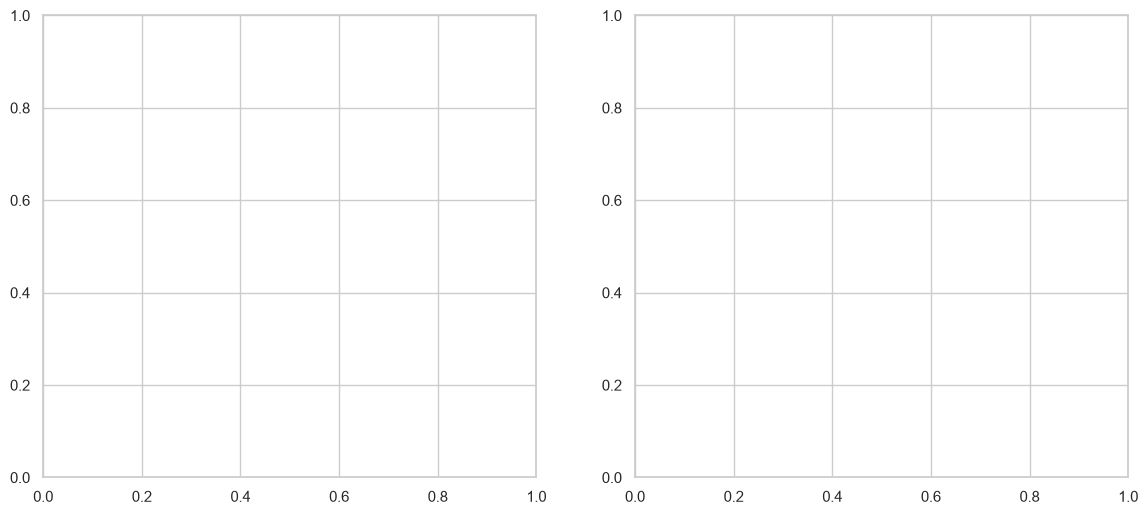

In [22]:
# Creo una figura con dos subgráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

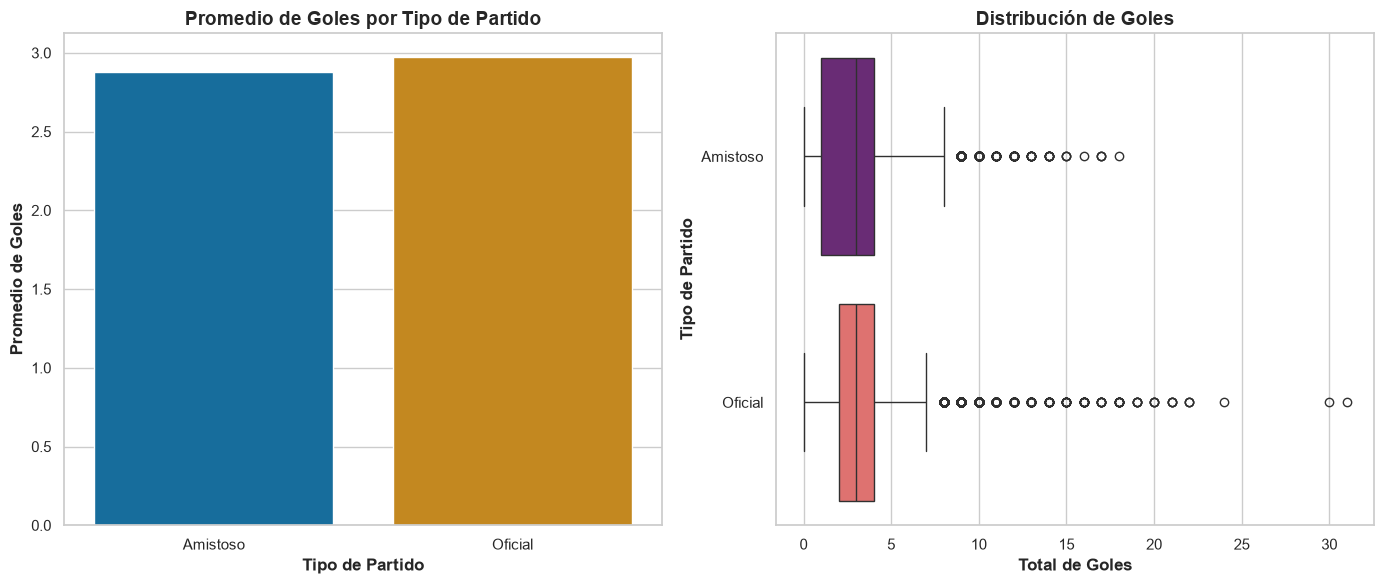

In [23]:
# 1. para evitar que matplotlib abra una ventana flotante del grafico en lugar de mostrarlo a pantalla, lo que quiero
%matplotlib inline 

# 2. Configuro estilo visual para presentación
sns.set_theme(style='whitegrid', palette='bright')

# 3. Creo el lienzo con 2 espacios (axes[0] y axes[1]), para crear dos graficos, uno de barras con los promedios 
# y otro de caja con las distribuciones de goles
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

# ==========================================
# GRÁFICO 1: Promedio de Goles por Tipo de Partido
# ==========================================
promedios = (
    resultados_limpio.groupby("tipo_partido")["total_goles"].mean().reset_index()
)

sns.barplot(
    data=promedios,
    x="tipo_partido",
    y="total_goles",
    hue="tipo_partido",
    ax=axes[0],
    palette="colorblind",
    legend=False
)

axes[0].set_title("Promedio de Goles por Tipo de Partido", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Tipo de Partido", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Promedio de Goles", fontsize=12, fontweight="bold")


# ==========================================
# GRÁFICO 2: Boxplot de la distribución de goles (en axes[1])
# ==========================================
sns.boxplot(
    data=resultados_limpio,
    x="total_goles",
    y="tipo_partido", 
    hue="tipo_partido", # Requerido por Seaborn moderno para evitar warnings
    ax=axes[1],
    palette="magma",
    legend=False
)

axes[1].set_title("Distribución de Goles", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Total de Goles", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Tipo de Partido", fontsize=12, fontweight="bold")


# 4. Ajusto el diseño forzando el renderizado en Jupyter
plt.tight_layout()
display(fig)  # Muestra la figura limpia en el notebook
plt.close(fig) # Cierra la figura en memoria para evitar duplicados

## La respuesta al planteamiento parece ser que si, aun que la diferencia sea muy pequeña. Cuando hay puntos en juego, las selecciones tienden a meter de media más goles que en las competiciones amistosas, donde se relajan un poquito más. Lo que se aprecian son los valores atipicos, en las competiciones amistosas hay partidos que han terminados por goleadas supuestamente en los dos tiempos reglamentarios, mientas que en los oficiales hay partidos que han terminado con más de 30 goles, quizás despues de interminables tandas de penalties.

## 1. DINAMICAS Y MOMENTOS DE GOLES
## 1.2 Tramos de partido: ¿En qué tramo exacto (ej. 0-15'..... 75-90') se concentra la mayor cantidad de goles? ¿Se confirma que la segunda mitad es más prolífica?

## uso el df "marcadores_limpio" donde aparece el minuto de partido donde se ha marcado el tanto

In [36]:
display(marcadores_limpio.tail())

,date,home_team,away_team,team,scorer,minute,own_goal,penalty,tramo
47909,2026-07-18,France,England,France,Kylian MbappÃ©,66.0,False,False,61-75
47910,2026-07-18,France,England,England,Bukayo Saka,87.0,False,True,76-90+
47911,2026-07-18,France,England,France,Ousmane DembÃ©lÃ©,90.0,False,False,76-90+
47912,2026-07-18,France,England,England,Jude Bellingham,90.0,False,False,76-90+
47913,2026-07-19,Spain,Argentina,Spain,Ferran Torres,106.0,False,False,Prórroga


In [26]:
print(marcadores_limpio.shape)

(47914, 8)


## El nr. totales de goles es de 47914, incluidos penalties y goles en propria puerta

In [32]:
# compruebo de que está compuesta la columna "minute"

print(marcadores_limpio["minute"].value_counts(dropna=False))

minute
90.0     2077
45.0     1087
89.0      721
75.0      656
88.0      651
         ... 
107.0       4
96.0        4
113.0       3
99.0        3
122.0       1
Name: count, Length: 122, dtype: int64


In [35]:
print(marcadores_limpio["minute"].sample(10))

print(marcadores_limpio["minute"].dtype)

print(marcadores_limpio["minute"].unique())

21706     40.0
20791     21.0
22819     28.0
43153     13.0
1481      50.0
43957     45.0
38468     90.0
291       16.0
46056    115.0
45900     58.0
Name: minute, dtype: str
str
<StringArray>
[ '44.0',  '55.0',  '70.0',  '75.0',   '2.0',  '60.0',  '62.0',  '67.0',
  '81.0',  '29.0',
 ...
 '120.0', '100.0', '108.0', '117.0',  '98.0',  '92.0', '115.0', '119.0',
 '106.0',  '99.0']
Length: 122, dtype: str


In [ ]:
# tengo que pasar los valores de "minute" de str a int

# 1. Transformo a texto, quito el tiempo extra (ej. "90+2" -> "90") y limpio el ".0"

minuto_limpio = (
    marcadores_limpio["minute"]
    .astype(str)
    .str.split("+")
    .str[0]  # Se queda con la primera parte antes del '+'
    .str.replace(".0", "", regex=False))  # Quito los decimales '.0' si los hay

# 2. Convierto el resultado final a número
minuto_base = pd.to_numeric(minuto_limpio, errors="coerce")

# defino los rangos del partido

rangos = [(0, 15), (16, 30), (31, 45), (46, 60), (61, 75), (76, 90)]
condiciones = [
    minuto_base.between(inicio, fin).fillna(False).to_numpy(dtype=bool)
    for inicio, fin in rangos
]
condiciones.append((minuto_base > 90).fillna(False).to_numpy(dtype=bool))

# defino los tramos

tramos = ["0-15", "16-30", "31-45+", "46-60", "61-75", "76-90+", "Prórroga"]
marcadores_limpio["tramo"] = np.select(
    condiciones,
    tramos,
    default="Sin dato"
)

print("\n--- Goles por tramo de 15 min (frequencia) ---")
print(
    marcadores_limpio["tramo"]
    .value_counts()
    .reindex(tramos + ["Sin dato"], fill_value=0)
    .sort_values(ascending=False)
)


--- Goles por tramo de 15 min (frequencia) ---
tramo
76-90+      10241
61-75        8082
31-45+       8015
46-60        7905
16-30        6978
0-15         6175
Prórroga      264
Sin dato      254
Name: count, dtype: int64


## El tramo de partido donde estadisticamente se marcan más goles son los ultimos 15 minutos del partido: 76-90+ con 10241 goles, el 20% aprox del total

## Comprobamos si la segunda mitad del partido es la más prolifica

In [ ]:
# 1. Creo primero la columna 'minuto_base' en marcadores_limpio
marcadores_limpio["minuto_base"] = pd.to_numeric(
    marcadores_limpio["minute"]
    .astype(str)
    .str.split("+")
    .str[0]
    .str.replace(".0", "", regex=False),
    errors="coerce",
)


# 2. Función para clasificar cada gol en su respectiva mitad, los NaN si hay los meto como desconocidos
def clasificar_mitad(minuto):
  if pd.isna(minuto):
    return "Desconocido"
  elif minuto <= 45:
    return "Primer Tiempo (1-45)"
  else:
    return "Segundo Tiempo (46+)"

# 3. Aplico la clasificación
marcadores_limpio["mitad"] = marcadores_limpio["minuto_base"].apply(
    clasificar_mitad
)

# 4. Resumen de goles y porcentajes
conteo_goles = marcadores_limpio["mitad"].value_counts()
porcentajes = marcadores_limpio["mitad"].value_counts(normalize=True) * 100

resumen_mitades = pd.DataFrame(
    {"Cantidad de Goles": conteo_goles, "Porcentaje (%)": porcentajes.round(2)}
)

print(resumen_mitades)

                      Cantidad de Goles  Porcentaje (%)
mitad                                                  
Segundo Tiempo (46+)              26492           55.29
Primer Tiempo (1-45)              21168           44.18
Desconocido                         254            0.53


## Los datos confirman la hipotesis, ya que el segundo tiempo de los partidos es donde más goles se meten: 55% vs 44%

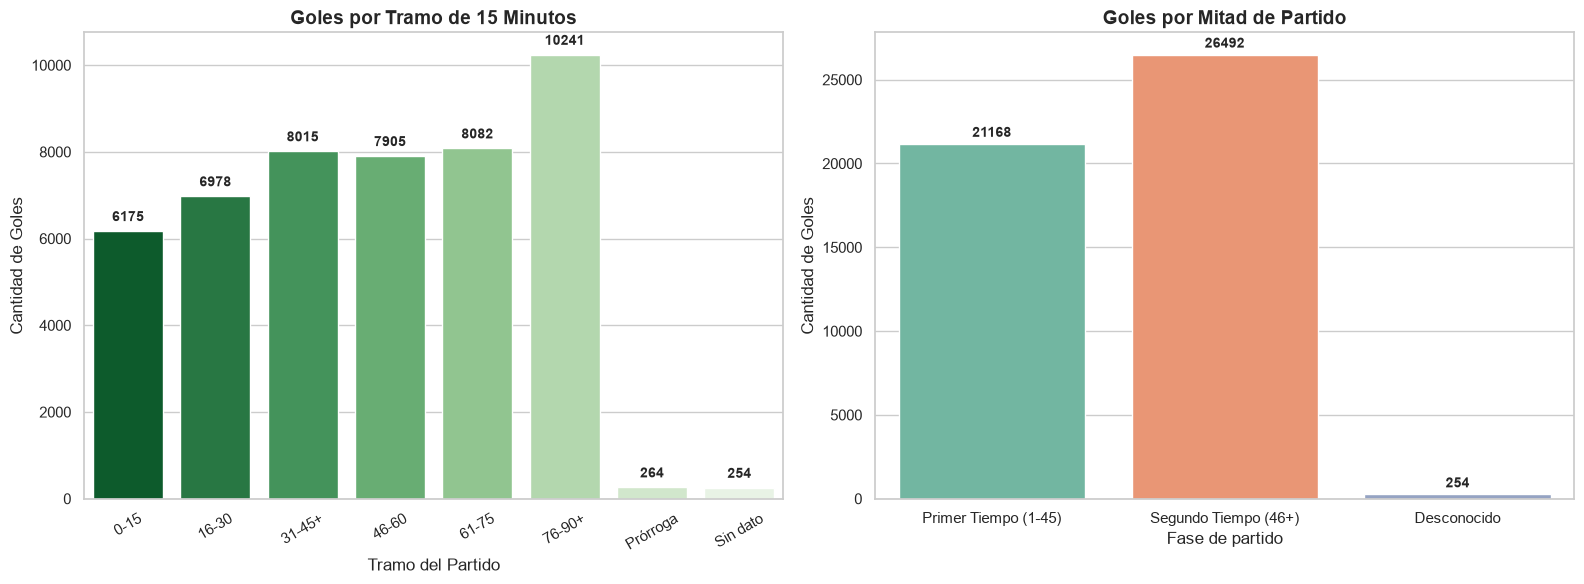

In [68]:
# dos graficos, uno para goles por tramos, otro para goles por tiempo

# Configuración estética
sns.set_theme(style="whitegrid")

# --- 1. DATOS PARA EL GRÁFICO DE TRAMOS DE 15 MINUTOS ---
datos_tramos = {
    "Tramo": [
        "0-15",
        "16-30",
        "31-45+",
        "46-60",
        "61-75",
        "76-90+",
        "Prórroga",
        "Sin dato",
    ],
    "Cantidad": [6175, 6978, 8015, 7905, 8082, 10241, 264, 254],
}
df_tramos = pd.DataFrame(datos_tramos)

# --- 2. DATOS PARA EL GRÁFICO DE MITADES ---
datos_mitades = {
    "Mitad": [
        "Primer Tiempo (1-45)",
        "Segundo Tiempo (46+)",
        "Desconocido",
    ],
    "Cantidad": [21168, 26492, 254],
}
df_mitades = pd.DataFrame(datos_mitades)

# Creo la figura con 2 gráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO 1: Goles por tramo de 15 minutos ---
sns.barplot(
    data=df_tramos,
    x="Tramo",
    y="Cantidad",
    hue="Tramo",
    palette="Greens_r",
    legend=False,
    ax=axes[0]
)
axes[0].set_title(
    "Goles por Tramo de 15 Minutos", fontsize=14, fontweight="bold"
)
axes[0].set_xlabel("Tramo del Partido", fontsize=12)
axes[0].set_ylabel("Cantidad de Goles", fontsize=12)
axes[0].tick_params(axis="x", rotation=30)

# Etiquetas con el valor exacto sobre cada barra del Gráfico 1
for p in axes[0].patches:
  axes[0].annotate(
      f"{int(p.get_height())}",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
      xytext=(0, 5),  # Desplazamiento vertical
      textcoords="offset points",
  )

# --- GRÁFICO 2: Goles por Mitad ---
sns.barplot(
    data=df_mitades,
    x="Mitad",
    y="Cantidad",
    hue="Mitad",
    palette="Set2",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Goles por Mitad de Partido", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Fase de partido", fontsize=12)
axes[1].set_ylabel("Cantidad de Goles", fontsize=12)

# Etiquetas con el valor exacto sobre cada barra del Gráfico 2
for p in axes[1].patches:
  axes[1].annotate(
      f"{int(p.get_height())}",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
      xytext=(0, 3),
      textcoords="offset points",
  )

# Diseño general
plt.tight_layout()
plt.show()

## =================================================================================================================

## 2. EL PESO REAL DEL "FACTOR CAMPO"

## ¿Qué porcentaje extra de victorias otorga jugar en casa en comparación con hacerlo en un estadio neutral?

In [ ]:
# tengo los datos en el df resultados_limpio
# me saco un display del df para entender de donde sacar la info

display(resultados_limpio.head())

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,total_goles,tipo_partido
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False,0,Amistoso
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False,6,Amistoso
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False,3,Amistoso
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False,4,Amistoso
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False,3,Amistoso


In [60]:
display(resultados_limpio.tail(25))

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral,total_goles,tipo_partido,resultado
49920,2026-10-06,China,Tajikistan,0,1,Friendly,Chongqing,China,False,1,Amistoso,Visitante
49921,2026-10-06,Russia,Nigeria,3,3,Friendly,Nizhniy Novgorod,Russia,False,6,Amistoso,Empate
49922,2026-10-06,Colombia,Peru,2,0,Friendly,Miami Gardens,United States,True,2,Amistoso,Local
49923,2026-10-06,India,Uruguay,1,6,Friendly,Kolkota,India,False,7,Amistoso,Visitante
49924,2026-10-06,Jordan,Venezuela,0,0,Friendly,Amman,Jordan,False,0,Amistoso,Empate
49925,2026-10-06,South Korea,Uzbekistan,2,0,Friendly,Yongin,South Korea,False,2,Amistoso,Local
49926,2026-10-06,Mexico,Chile,0,2,Friendly,Los Angeles,United States,True,2,Amistoso,Visitante
49927,2026-10-06,United States,Canada,1,0,Friendly,Saint Paul,United States,False,1,Amistoso,Local
49928,2026-10-06,England,Czech Republic,3,0,UEFA Nations League,London,England,False,3,Oficial,Local
49929,2026-10-06,Croatia,Spain,1,2,UEFA Nations League,Split,Croatia,False,3,Oficial,Visitante


In [64]:
# 1. Creo una columna que dice True si ganó el local, y False si no
resultados_limpio["home_win"] = resultados_limpio["home_score"] > resultados_limpio["away_score"]

# 2. Agrupo por campo neutral (False = en casa, True = en campo neutral) y saco el promedio (%)
porcentajes = resultados_limpio.groupby("neutral")["home_win"].mean() * 100

# 3. Guardo cada valor (redondeado) y calculo la diderencia
pct_casa = round(porcentajes[False], 2)      # Neutral = False (Jugando en casa)
pct_neutral = round(porcentajes[True], 2)    # Neutral = True  (Campo neutral)
diferencia = round(pct_casa - pct_neutral, 2)

# 4. Muestro los resultados

print("Victorias en casa:", pct_casa, "%")

print("Victorias en campo neutral:", pct_neutral, "%")

print("Victorias extra por jugar en casa:", diferencia, "%")

Victorias en casa: 50.73 %
Victorias en campo neutral: 44.22 %
Victorias extra por jugar en casa: 6.51 %


## El "factor campo" otorga un 6,5% de chances suplementarias de ganar por parte del equipo de casa, respecto a jugar ese mismo partito en un campo neutral. Así que se confirma el "efecto Anoeta, San Mamés, Mendizorroza" o el "efecto San Siro"....

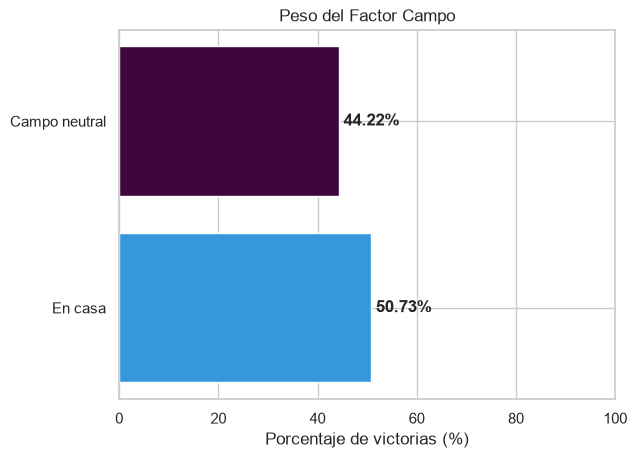

In [65]:
# saco el grafico, la libreria matplotlib ya la tengo cargada de antes

categorias = ["En casa", "Campo neutral"]
valores = [pct_casa, pct_neutral]

# 1. Crear gráfico de barras horizontales (barh)
plt.barh(categorias, valores, color=["#3498db", "#3E053F"])

# 2. Etiquetas y límites
plt.xlabel("Porcentaje de victorias (%)")
plt.xlim(0, 100)
plt.title("Peso del Factor Campo")

# 3. Añado el numero exacto al lado de cada barra para que se lea mejor
for i, v in enumerate(valores):
    plt.text(v + 1, i, f"{v}%", va='center', fontweight='bold')

# 4. Mostrar el gráfico
plt.show()

## =================================================================================================================


## 3. DOMINIO HISTORICO Y RIVALIDADES


## 3.1 ¿Cuáles son las selecciones con mayor cantidad de victorias acumuladas en competiciones oficiales?

In [ ]:
# los datos los tengo en resultados_limpio, 
# 1: tengo que filtrar e excluir los partidos amistosos (columna "tournament") 
# 2: compruebo la seleccion que ha ganado mas encuentros (como local o visitante)
# 3: cuento las victorias totales por pais

# filtro los amistosos, me hago una copia del df

oficiales = resultados_limpio[resultados_limpio["tournament"] != "Friendly"].copy()

In [71]:
# Creo una columna 'ganador' con el nombre de la selección ganadora

oficiales["ganador"] = None
oficiales.loc[oficiales["home_score"] > oficiales["away_score"], "ganador"] = oficiales["home_team"]
oficiales.loc[oficiales["away_score"] > oficiales["home_score"], "ganador"] = oficiales["away_team"]

In [74]:
# Cuento las victorias por selección (ignorando los empates donde ganador es None)

top_victorias = oficiales["ganador"].value_counts().head(20)

In [75]:
print("--- Top 20 selecciones con más victorias oficiales ---")
print(top_victorias)

--- Top 20 selecciones con más victorias oficiales ---
ganador
England        399
South Korea    394
Argentina      393
Brazil         382
Uruguay        304
Scotland       297
Mexico         295
Thailand       292
Sweden         290
Germany        286
Spain          286
Japan          286
Italy          281
Malaysia       274
France         262
Netherlands    258
Iran           252
Denmark        248
Egypt          245
Costa Rica     245
Name: count, dtype: int64


## Sorpresa Corea del Sur.......mejor que Argentina! habria que filtrar más fino porque quizás Corea del Sur tenga más partidos eliminatorios respecto a otras selecciones

In [118]:
# 1. Creo la función para clasificar cada torneo en tipologías

def clasificar_torneo(nombre):
    nombre_lower = str(nombre).lower()
    if 'friendly' in nombre_lower:
        return 'Amistoso'
    elif 'world cup qualification' in nombre_lower or 'qualification' in nombre_lower:
        return 'Eliminatorias / Clasificación'
    elif 'world cup' in nombre_lower:
        return 'Copa del Mundo (Fase Final)'
    elif any(copa in nombre_lower for copa in ['euro', 'copa américa', 'african cup', 'asian cup', 'gold cup', 'nations cup', 'championship']):
        return 'Torneo Continental'
    else:
        return 'Otros / Regionales'

resultados_limpio['tipo_torneo'] = resultados_limpio['tournament'].apply(clasificar_torneo)

# 2. Determino la selección más ganadora por cada partido

resultados_limpio['ganador'] = None
resultados_limpio.loc[resultados_limpio['home_score'] > resultados_limpio['away_score'], 'ganador'] = resultados_limpio['home_team']
resultados_limpio.loc[resultados_limpio['away_score'] > resultados_limpio['home_score'], 'ganador'] = resultados_limpio['away_team']

# 3. Agrupo por tipología y por selección, cuento las victorias y ordeno

victorias_por_tipo = (
    resultados_limpio.dropna(subset=['ganador'])
    .groupby(['tipo_torneo', 'ganador'])
    .size()
    .reset_index(name='total_victorias')
)

# Quito la categoria Amistoso

victorias_por_tipo = victorias_por_tipo[victorias_por_tipo['tipo_torneo'] != 'Amistoso']

# saco los resultados, los primeros cinco equipos por tipo de torneo

top_5_por_tipo = (
    victorias_por_tipo.sort_values(['tipo_torneo', 'total_victorias'], ascending=[True, False])
    .groupby('tipo_torneo')
    .head(5)
)

print(top_5_por_tipo.to_string(index=False)) 

                  tipo_torneo     ganador  total_victorias
  Copa del Mundo (Fase Final)      Brazil               79
  Copa del Mundo (Fase Final)     Germany               70
  Copa del Mundo (Fase Final)   Argentina               54
  Copa del Mundo (Fase Final)      France               45
  Copa del Mundo (Fase Final)       Italy               45
Eliminatorias / Clasificación       Spain              188
Eliminatorias / Clasificación Netherlands              179
Eliminatorias / Clasificación     England              164
Eliminatorias / Clasificación     Germany              164
Eliminatorias / Clasificación       Italy              163
           Otros / Regionales   Argentina              234
           Otros / Regionales South Korea              205
           Otros / Regionales     Uruguay              192
           Otros / Regionales      Brazil              191
           Otros / Regionales    Malaysia              180
           Torneo Continental     England              1

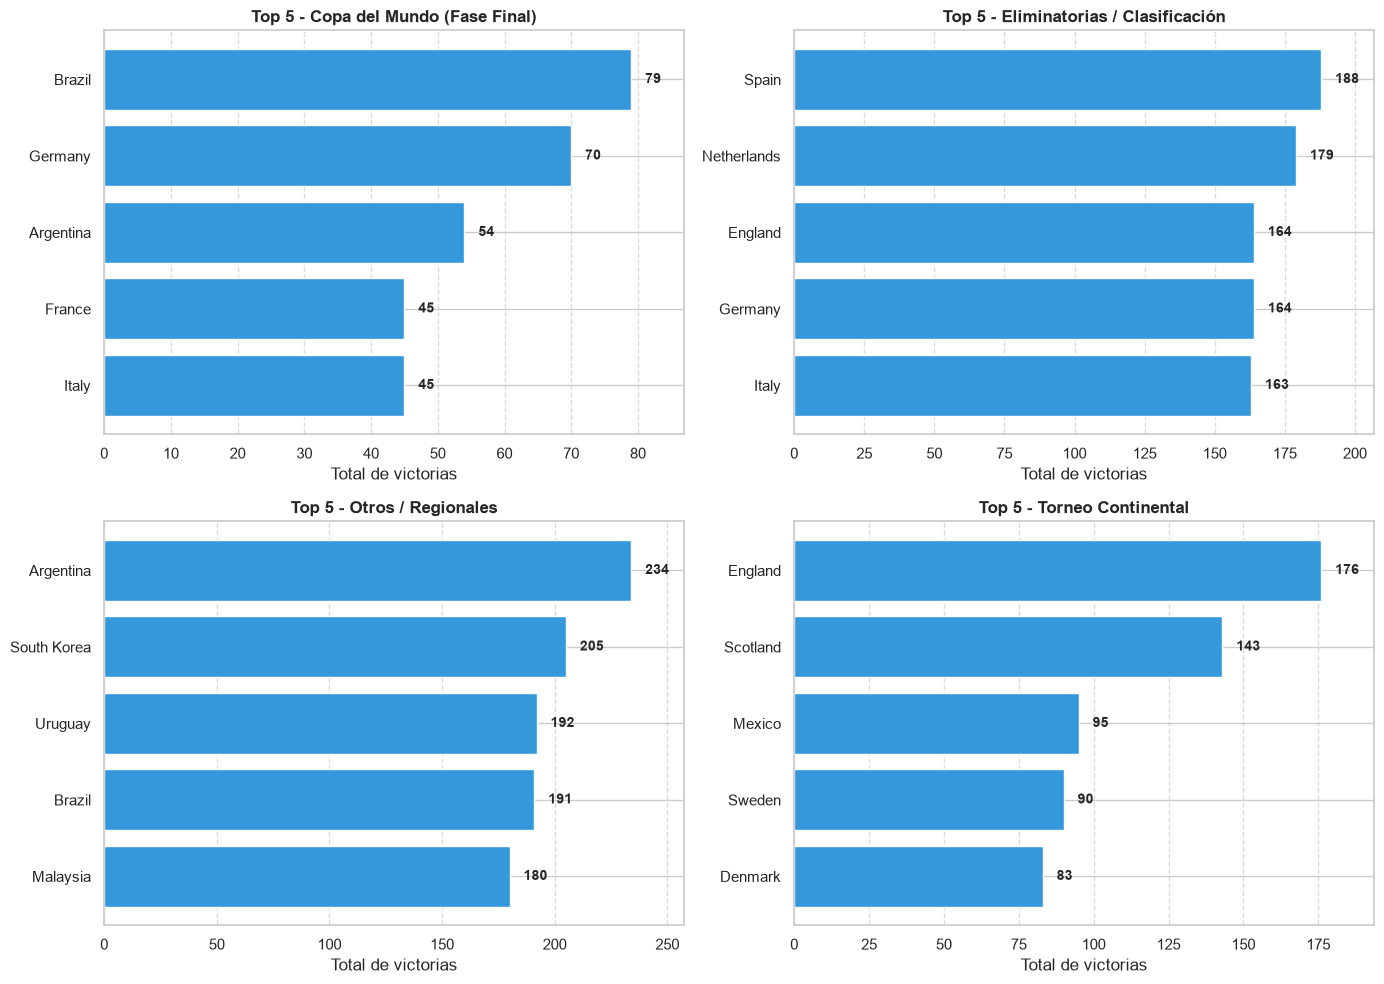

In [123]:
# saco el grafico creando varios subgraficos por tipologia de torneo, con barras horizontales

# 1. Saco las tipologías únicas de torneos

tipologias = top_5_por_tipo['tipo_torneo'].unique()
num_tipologias = len(tipologias)

# 2. Configuro una cuadrícula de subgráficos (necesito 4 subgraficos, los voy a poner en una cuadricola de 2 filas x 2 columnas)

filas = (num_tipologias + 1) // 2
fig, axes = plt.subplots(nrows=filas, ncols=2, figsize=(14, 10))
axes = axes.flatten()

# 3. Dibujo un gráfico de barras para cada tipología

for i, tipo in enumerate(tipologias):
    ax = axes[i]
    datos_tipo = top_5_por_tipo[top_5_por_tipo['tipo_torneo'] == tipo].iloc[::-1]
    
    # Guardo las barras en una variable 'barras'

    barras = ax.barh(datos_tipo['ganador'], datos_tipo['total_victorias'], color="#3498db")
    
    # Añado los números exactos al final de cada barra con un pequeño margen (padding)

    ax.bar_label(barras, padding=10, fontweight='bold', fontsize=10)
    
    # Amplio un poco el límite derecho del eje X (10% extra) para que los números no se corten
    
    ax.set_xlim(0, datos_tipo['total_victorias'].max() * 1.10)
    
    ax.set_title(f"Top 5 - {tipo}", fontweight='bold')
    ax.set_xlabel("Total de victorias")
    ax.grid(axis='x', linestyle='--', alpha=0.7)

# 4. Ajusto e imprimo
plt.tight_layout()
plt.show()

## 3.2 La "Bestia Negra": ¿cuál es el rival contra el que una selección específica tiene el peor balance de derrotas?

In [11]:
resultados_limpio = dataframes["resultados_limpio"]
resultados_limpio.info()

<class 'pandas.DataFrame'>
RangeIndex: 49945 entries, 0 to 49944
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        49945 non-null  datetime64[us]
 1   home_team   49945 non-null  str           
 2   away_team   49945 non-null  str           
 3   home_score  49945 non-null  int64         
 4   away_score  49945 non-null  int64         
 5   tournament  49945 non-null  str           
 6   city        49945 non-null  str           
 7   country     49945 non-null  str           
 8   neutral     49945 non-null  bool          
dtypes: bool(1), datetime64[us](1), int64(2), str(5)
memory usage: 3.1 MB


#### Tengo que conseguir sacar los datos de los partidos desde el punto de vista de cada seleccion. En el df una seleccion juga a veces en casa (home_team) o fuera (away_team)

#### - Selecciono los datos basicos de cada partido, y los renombro desde el punto de vista del equipo local

In [ ]:
# hago una copia de resultados_limpio para no modificar los datos

df_local = resultados_limpio[["date", "home_team", "away_team", "home_score", "away_score"]].copy()
df_local.columns = ["fecha", "seleccion", "rival", "goles_favor", "goles_contra"]

#### - lo mismo, pero desde el punto de vista del equipo cuando juega de visitante, fuera de casa

In [20]:
# el equipo visitante es la seleccion que quiero sacar los datos, tengo que hacer el reves
df_away = resultados_limpio[["date", "away_team", "home_team", "away_score", "home_score"]].copy()
df_away_columns = ["fecha", "seleccion", "rival", "goles_favor", "goles_contra"]

In [ ]:
# uno los dos nuevos df haciendo un concatenado

df_unificado = pd.concat([df_local, df_away], ignore_index=True)

# ahora tengo un unico df con dos veces el mismo partido, uno desde el punto de vista local, el otro rival

#### - marco las derrotas de forma rapida y automatica

In [25]:
# comparo la columna goles en contra vs a favor, si son > ma da un True
# el True/Felse lo paso a int 1 (si derrota) o 0 (si victoria) con astype(int)

df_unificado["derrota"] = (df_unificado["goles_contra"]>df_unificado["goles_favor"]).astype(int)

In [28]:
print(df_unificado["derrota"].value_counts())

derrota
0    85759
1    14131
Name: count, dtype: int64


In [97]:
def obtener_bestia_negra(nombre_seleccion):
    sub = df_unificado[df_unificado["seleccion"] == nombre_seleccion] # filtro solo por el pais buscado

    resumen = (
      sub.groupby("rival")["derrota"]
      .agg(derrotas="sum", total_partidos="count")
      .reset_index()
    )

    resumen["%_derrotas"] = ((resumen["derrotas"] / resumen["total_partidos"])*100).round(1)

    return resumen.sort_values(by="derrotas", ascending=False, ignore_index=True).iloc[0]

In [128]:
pd.DataFrame([obtener_bestia_negra("Brazil")])

,rival,derrotas,total_partidos,%_derrotas
0,Argentina,13,50,26.0


In [129]:
def ranking_derrotas(nombre_seleccion):
    sub = df_unificado[df_unificado["seleccion"] == nombre_seleccion] # filtro solo por el pais buscado

    resumen = (
      sub.groupby("rival")["derrota"]
      .agg(derrotas="sum", total_partidos="count")
      .reset_index()
    )

    resumen["%_derrotas"] = ((resumen["derrotas"] / resumen["total_partidos"])*100).round(1)

    return resumen.sort_values(by="%_derrotas", ascending=False, ignore_index=True).head(15)

## Los datos se pueden interpretar en funcion si miramos por el nr. de derrotas absolutas o %, 
## ej. miramos a Brazil, su "bestia negra" en terminos de derrotas es - obviamente - Argentina, con 13 derrotas en 50 partidos, pero en teminos % sería Noruega que en dos partidos disputados siempre le ha ganado a Brazil 

In [130]:
ranking_derrotas("Brazil")

,rival,derrotas,total_partidos,%_derrotas
0,Norway,2,2,100.0
1,Hungary,2,3,66.7
2,Belgium,1,3,33.3
3,Senegal,1,3,33.3
4,France,2,7,28.6
5,Argentina,13,50,26.0
6,Netherlands,1,5,20.0
7,Honduras,1,5,20.0
8,Uruguay,9,49,18.4
9,Spain,1,6,16.7


### voy a sacar, para cada selección del mundo, cuál es el rival que más la ha castigado al rival directo

In [136]:
# 1. Agrupo todos los enfrentamientos del dataset
todos_enfrentamientos = (
    df_unificado.groupby(["seleccion", "rival"])["derrota"]
    .agg(derrotas="sum", total_partidos="count")
    .reset_index()
)

# 2. Saco el peor rival (máximas derrotas) para cada selección
ranking_mundial = (
    todos_enfrentamientos.sort_values(
        by=["seleccion", "derrotas"], ascending=[True, False]
    )
    .drop_duplicates(subset=["seleccion"])
    .sort_values(by='derrotas', ascending=False)
)

# 3. Calculo el porcentaje redondeado
ranking_mundial["%_derrotas"] = ((ranking_mundial["derrotas"] / ranking_mundial["total_partidos"])*100).round(2)

print('=== RANKING ABSOLUTO: LA PEOR BESTIA NEGRA DE CADA PAÍS ===')
display(ranking_mundial.head(15))

=== RANKING ABSOLUTO: LA PEOR BESTIA NEGRA DE CADA PAÍS ===


,seleccion,rival,derrotas,total_partidos,%_derrotas
8107,Northern Ireland,England,35,49,71.43
12029,Wales,England,33,51,64.71
3744,Finland,Sweden,30,45,66.67
4571,Guernsey,Jersey,28,59,47.46
8236,Norway,Sweden,26,58,44.83
679,Austria,Hungary,25,69,36.23
2182,Chile,Uruguay,24,51,47.06
5774,Jersey,Guernsey,24,60,40.00
6770,Malawi,Zambia,24,46,52.17
11788,Uruguay,Argentina,23,84,27.38


## saco los graficos de ranking derrotas

In [137]:
import matplotlib.pyplot as plt
import seaborn as sns

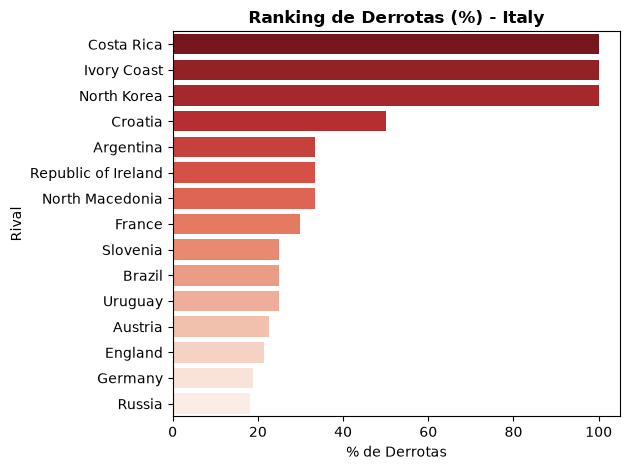

In [156]:
def ranking_derrotas(nombre_seleccion):
    sub = df_unificado[df_unificado["seleccion"] == nombre_seleccion]

    resumen = (
        sub.groupby("rival")["derrota"]
        .agg(derrotas="sum", total_partidos="count")
        .reset_index()
    )

    resumen["%_derrotas"] = (
        resumen["derrotas"] / resumen["total_partidos"] * 100
    ).round(1)

    return resumen.sort_values(
        by="%_derrotas", ascending=False, ignore_index=True
    ).head(15)


nombre_seleccion = "Italy"  # Cambia por la selección que quieras
resultado = ranking_derrotas(nombre_seleccion).sort_values(
    "%_derrotas", ascending=False
)
orden_rivales = resultado["rival"].tolist()

sns.barplot(
    data=resultado,
    x="%_derrotas",
    y="rival",
    order=orden_rivales,
    hue="rival",
    palette="Reds_r",
    legend=False,
)

plt.title(f"Ranking de Derrotas (%) - {nombre_seleccion}", fontweight="bold")
plt.xlabel("% de Derrotas")
plt.ylabel("Rival")
plt.tight_layout()
plt.show()